This script looks at how similar children's drawings are to adults over time

In [1]:
library(tidyverse)
library(viridis)

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.6
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.1     ✔ tibble    3.3.0
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.2.0     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
Loading required package: viridisLite



In [2]:
merged_drawings <- read_csv("../data/tidy/drawings.csv") %>%
  filter(draw_exists == 1, draw_interference == 0)

Rows: 638 Columns: 31
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr  (5): participant_id, target_category, bounding_box, draw_full_features,...
dbl (24): age_months, age_yrs, draw_exists, draw_interference, trial_duratio...
lgl  (2): is_adult, is_child

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [3]:
sea_animal_categories <- c("crab", "octopus", "seahorse", "shark", "turtle", "whale")

In [4]:
full_drawings_plot <- merged_drawings %>%
  filter(str_starts(participant_id, "BD")) %>%
  mutate(
    target_category = str_trim(str_to_lower(target_category))
  ) %>%
  filter(target_category %in% sea_animal_categories) %>%
  select(
    participant_id,
    age_months,
    target_category,
    draw_half_cossim_adults,
    draw_cossim_adults
  ) %>%
  pivot_longer(
    cols = c(draw_half_cossim_adults, draw_cossim_adults),
    names_to = "draw_timepoint",
    values_to = "cosine_similarity_to_adults"
  ) %>%
  mutate(
    draw_timepoint = recode(
      draw_timepoint,
      draw_half_cossim_adults = "50% draw",
      draw_cossim_adults = "100% draw"
    ),
    draw_timepoint = factor(
      draw_timepoint,
      levels = c("50% draw", "100% draw")
    ),
    age_yrs = age_months / 12
  ) %>%
  group_by(target_category) %>%
  mutate(
    cosine_similarity_to_adults = (cosine_similarity_to_adults - mean(cosine_similarity_to_adults, na.rm = TRUE)) /
                                   sd(cosine_similarity_to_adults, na.rm = TRUE)
  ) %>%
  ungroup()

Warning message:
“Removed 3 rows containing non-finite outside the scale range
(`stat_summary()`).”
Warning message:
“Removed 3 rows containing non-finite outside the scale range
(`stat_summary()`).”
Warning message:
“Removed 3 rows containing missing values or values outside the scale range
(`geom_line()`).”
Warning message:
“Removed 3 rows containing missing values or values outside the scale range
(`geom_point()`).”
Warning message:
“Removed 3 rows containing non-finite outside the scale range
(`stat_summary()`).”
Warning message:
“Removed 3 rows containing non-finite outside the scale range
(`stat_summary()`).”
Warning message:
“Removed 3 rows containing missing values or values outside the scale range
(`geom_line()`).”
Warning message:
“Removed 3 rows containing missing values or values outside the scale range
(`geom_point()`).”


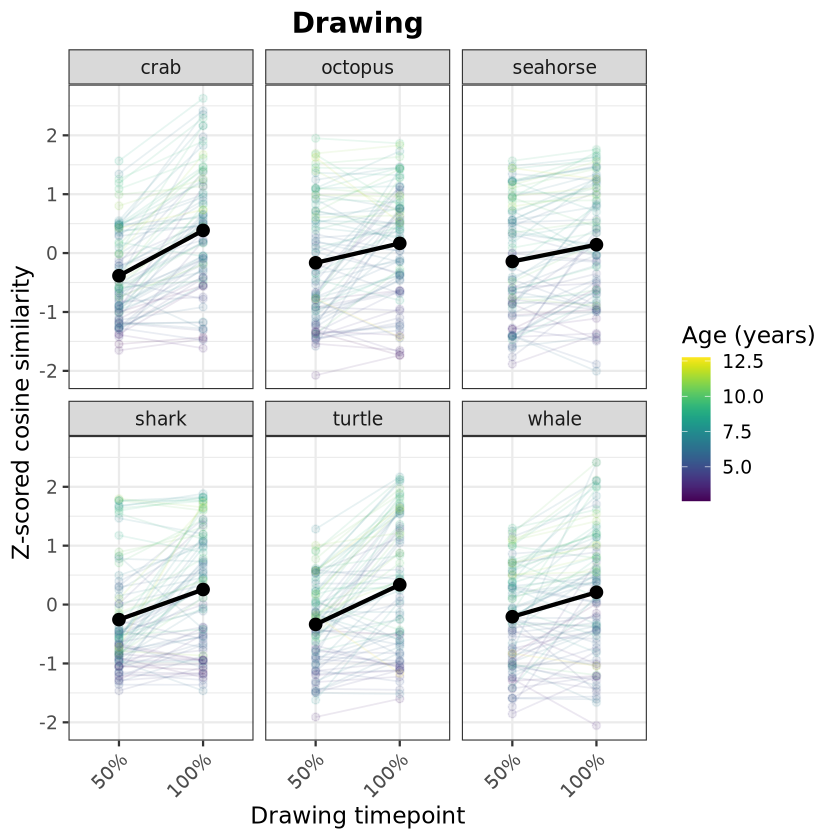

In [5]:
ggplot(
  full_drawings_plot,
  aes(
    x = draw_timepoint,
    y = cosine_similarity_to_adults,
    group = interaction(participant_id, target_category),
    color = age_yrs
  )
) +
  geom_line(alpha = 0.1, linewidth = 0.5) +
  geom_point(alpha = 0.1, size = 1.8) +
  stat_summary(
    aes(group = 1),
    fun = mean,
    geom = "line",
    color = "black",
    linewidth = 1.2
  ) +
  stat_summary(
    aes(group = 1),
    fun = mean,
    geom = "point",
    color = "black",
    size = 3
  ) +
  facet_wrap(~ target_category) +
  scale_color_viridis(
    name = "Age (years)",
    option = "viridis"
  ) +
  scale_x_discrete(labels = c("50% draw" = "50%", "100% draw" = "100%")) +
  labs(
    title = "Drawing",
    x = "Drawing timepoint",
    y = "Z-scored cosine similarity"
  ) +
  theme_bw(base_size = 14) +
  theme(
    plot.title = element_text(hjust = 0.5, face = "bold"),
    axis.text.x = element_text(angle = 45, hjust = 1)
  )

ggsave(
  "../figures/drawing_similarity_to_adults_over_time.png",
  width = 6,
  height = 8,
  dpi = 300
)

In [6]:
library(lme4)

Loading required package: Matrix




Attaching package: ‘Matrix’


The following objects are masked from ‘package:tidyr’:

    expand, pack, unpack




In [7]:
drawing_time_model <- lmer(
  cosine_similarity_to_adults ~ draw_timepoint + scale(age_months) +
    (1 | participant_id),
  data = full_drawings_plot
)

summary(drawing_time_model)

Linear mixed model fit by REML ['lmerMod']
Formula: cosine_similarity_to_adults ~ draw_timepoint + scale(age_months) +  
    (1 | participant_id)
   Data: full_drawings_plot

REML criterion at convergence: 2147

Scaled residuals: 
    Min      1Q  Median      3Q     Max 
-3.1663 -0.7024 -0.0122  0.6456  2.9874 

Random effects:
 Groups         Name        Variance Std.Dev.
 participant_id (Intercept) 0.2182   0.4671  
 Residual                   0.4571   0.6761  
Number of obs: 963, groups:  participant_id, 88

Fixed effects:
                        Estimate Std. Error t value
(Intercept)             -0.27128    0.05896  -4.601
draw_timepoint100% draw  0.49696    0.04357  11.405
scale(age_months)        0.51269    0.05298   9.678

Correlation of Fixed Effects:
            (Intr) d_100d
drw_tm100%d -0.369       
scl(g_mnth)  0.042  0.000

In [8]:
#Let's collapse across categories and look at the overall trend across timepoints, z-scoring within category

library(tidyverse)

collapsed_drawings <- merged_drawings %>%
  filter(str_starts(participant_id, "BD")) %>%
  mutate(
    target_category = str_trim(str_to_lower(target_category)),
    age_yrs = age_months / 12
  ) %>%
  pivot_longer(
    cols = c(draw_half_cossim_adults, draw_cossim_adults),
    names_to = "draw_timepoint",
    values_to = "cosine_similarity"
  ) %>%
  mutate(
    draw_timepoint = recode(
      draw_timepoint,
      draw_half_cossim_adults = "50%",
      draw_cossim_adults = "100%"
    ),
    draw_timepoint = factor(draw_timepoint, levels = c("50%", "100%"))
  ) %>%
  group_by(target_category) %>%
  mutate(
    cossim_z = (cosine_similarity - mean(cosine_similarity, na.rm = TRUE)) /
               sd(cosine_similarity, na.rm = TRUE)
  ) %>%
  ungroup()

Warning message:
“Removed 3 rows containing non-finite outside the scale range
(`stat_summary()`).”
Warning message:
“Removed 3 rows containing non-finite outside the scale range
(`stat_summary()`).”


Warning message:
“Removed 3 rows containing missing values or values outside the scale range
(`geom_line()`).”
Warning message:
“Removed 3 rows containing missing values or values outside the scale range
(`geom_point()`).”
Warning message:
“Removed 3 rows containing non-finite outside the scale range
(`stat_summary()`).”
Warning message:
“Removed 3 rows containing non-finite outside the scale range
(`stat_summary()`).”
Warning message:
“Removed 3 rows containing missing values or values outside the scale range
(`geom_line()`).”
Warning message:
“Removed 3 rows containing missing values or values outside the scale range
(`geom_point()`).”


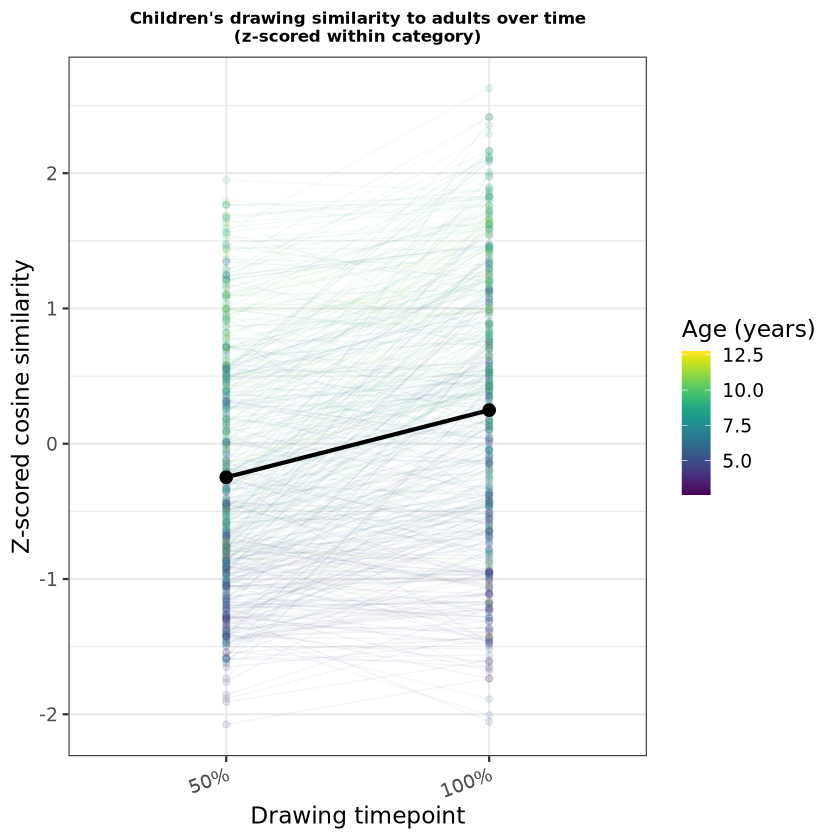

In [9]:
#Fig 11A
ggplot(
  collapsed_drawings,
  aes(
    x = draw_timepoint,
    y = cossim_z,
    group = interaction(participant_id, target_category),
    color = age_yrs
  )
) +
  geom_line(alpha = 0.05, linewidth = 0.4) +
  geom_point(alpha = 0.1, size = 1.5) +
  #facet_wrap(~ target_category) +
  scale_color_viridis(
    name = "Age (years)",
    option = "viridis"
  ) +
    stat_summary(
    aes(group = 1),
    fun = mean,
    geom = "line",
    color = "black",
    linewidth = 1.2
  ) +
  stat_summary(
    aes(group = 1),
    fun = mean,
    geom = "point",
    color = "black",
    size = 3
  ) +
  labs(
    title = "Children's drawing similarity to adults over time\n(z-scored within category)",
    x = "Drawing timepoint",
    y = "Z-scored cosine similarity"
  ) +
  theme_bw(base_size = 14) +
  theme(
    plot.title = element_text(hjust = 0.5, face = "bold", size = 10),
    axis.text.x = element_text(angle = 20, hjust = 1)
  )

  ggsave("../figures/collapsed_drawing_similarity_to_adults_over_time.png",
         width = 5,
         height = 5,
         dpi = 300)

In [10]:
collapsed_drawings <- collapsed_drawings %>%
  mutate(
    age_bin = ntile(age_yrs, 6),
    age_bin = factor(age_bin)
  ) %>%
  group_by(age_bin) %>%
  mutate(
    age_bin_label = paste0(
      round(min(age_yrs), 1), "–", round(max(age_yrs), 1)
    )
  ) %>%
  ungroup() %>%
  mutate(
    age_bin_label = factor(age_bin_label, levels = unique(age_bin_label[order(age_bin)]))
  )

Warning message:
“Removed 3 rows containing non-finite outside the scale range
(`stat_summary()`).”
Warning message:
“Removed 3 rows containing non-finite outside the scale range
(`stat_summary()`).”
Warning message:
“Removed 3 rows containing missing values or values outside the scale range
(`geom_line()`).”


Warning message:
“Removed 3 rows containing missing values or values outside the scale range
(`geom_point()`).”
Warning message:
“Removed 3 rows containing non-finite outside the scale range
(`stat_summary()`).”
Warning message:
“Removed 3 rows containing non-finite outside the scale range
(`stat_summary()`).”
Warning message:
“Removed 3 rows containing missing values or values outside the scale range
(`geom_line()`).”
Warning message:
“Removed 3 rows containing missing values or values outside the scale range
(`geom_point()`).”


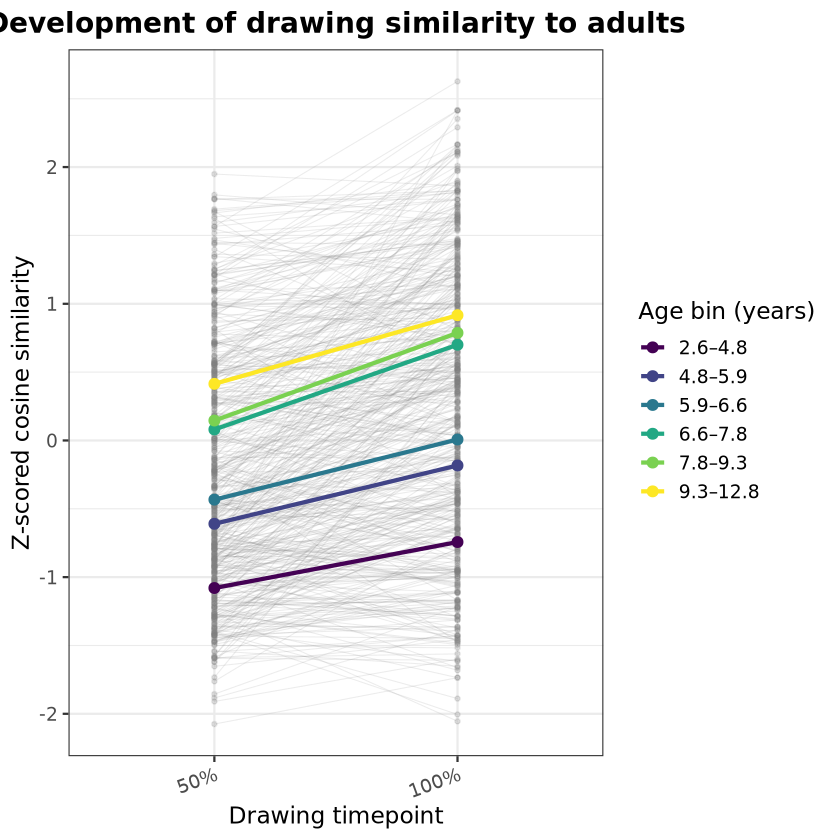

In [11]:
ggplot(
  collapsed_drawings,
  aes(
    x = draw_timepoint,
    y = cossim_z,
    group = interaction(participant_id, target_category), 
    color = age_bin_label
  )
) +
  # faint individual trajectories
  geom_line(alpha = 0.15, linewidth = 0.3, color = "grey50") +
  geom_point(alpha = 0.2, size = 1, color = "grey50") +

  # mean trend per age bin
  stat_summary(
    aes(color = age_bin_label, group = age_bin_label),
    fun = mean,
    geom = "line",
    linewidth = 1.2
  ) +
  stat_summary(
    aes(color = age_bin_label, group = age_bin_label),
    fun = mean,
    geom = "point",
    size = 2.5
  ) +

  scale_color_viridis_d(
    name = "Age bin (years)",
    option = "viridis"
  ) +

  labs(
    title = "Development of drawing similarity to adults",
    x = "Drawing timepoint",
    y = "Z-scored cosine similarity"
  ) +

  theme_bw(base_size = 14) +
  theme(
    plot.title = element_text(hjust = 0.5, face = "bold"),
    axis.text.x = element_text(angle = 20, hjust = 1)
  )

  ggsave(
    "../figures/drawing_similarity_to_adults_over_time_by_age_bin.png",
    width = 10,
    height = 6,
    dpi = 300
  )

In [12]:
interaction_model <- lmer(
  cossim_z ~ draw_timepoint * scale(age_months) +
    (1 | participant_id),
  data = collapsed_drawings
)

In [13]:
summary(interaction_model)

Linear mixed model fit by REML ['lmerMod']
Formula: cossim_z ~ draw_timepoint * scale(age_months) + (1 | participant_id)
   Data: collapsed_drawings

REML criterion at convergence: 2149

Scaled residuals: 
    Min      1Q  Median      3Q     Max 
-3.2591 -0.7003 -0.0064  0.6419  2.9930 

Random effects:
 Groups         Name        Variance Std.Dev.
 participant_id (Intercept) 0.2183   0.4672  
 Residual                   0.4563   0.6755  
Number of obs: 963, groups:  participant_id, 88

Fixed effects:
                                     Estimate Std. Error t value
(Intercept)                          -0.27126    0.05895  -4.601
draw_timepoint100%                    0.49692    0.04354  11.413
scale(age_months)                     0.47930    0.05727   8.369
draw_timepoint100%:scale(age_months)  0.06677    0.04350   1.535

Correlation of Fixed Effects:
            (Intr) dr_100% scl(_)
drw_tmp100% -0.369               
scl(g_mnth)  0.039  0.000        
dr_100%:(_)  0.000 -0.001  -0.380

`geom_smooth()` using formula = 'y ~ x'
Warning message:
“Removed 3 rows containing non-finite outside the scale range (`stat_smooth()`).”
Warning message:
“Removed 3 rows containing missing values or values outside the scale range
(`geom_point()`).”
`geom_smooth()` using formula = 'y ~ x'
Warning message:
“Removed 3 rows containing non-finite outside the scale range (`stat_smooth()`).”
Warning message:
“Removed 3 rows containing missing values or values outside the scale range
(`geom_point()`).”


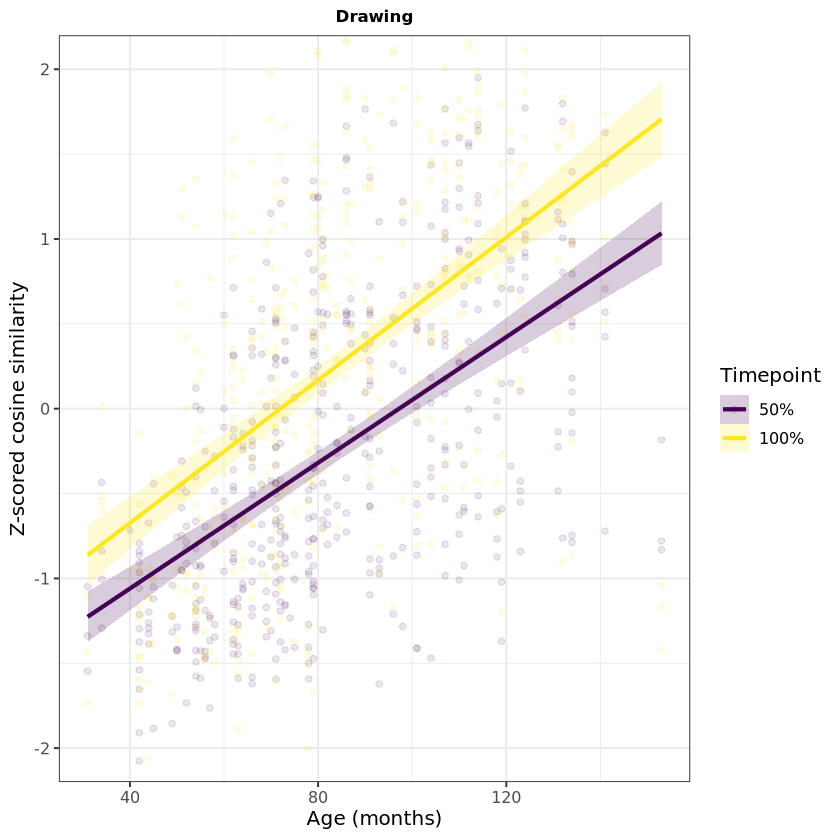

In [15]:
#Fib 12A
ggplot(collapsed_drawings, aes(
  x = age_months,
  y = cossim_z,
  color = draw_timepoint,
  fill = draw_timepoint
)) +
  geom_point(alpha = 0.1, size = 1.5) +
  geom_smooth(method = "lm", se = TRUE, linewidth = 1.2, alpha = 0.2) +
  scale_color_viridis_d(name = "Timepoint") +
  scale_fill_viridis_d(name = "Timepoint") +
  coord_cartesian(ylim = c(-2, 2)) +
  labs(
    x = "Age (months)",
    y = "Z-scored cosine similarity",
    title = "Drawing"
  ) +
  theme_bw(base_size = 12) +
  theme(plot.title = element_text(hjust = 0.5, face = "bold", size = 10))
  ggsave(
    "../figures/drawing_similarity_to_adults_over_time_interaction_plot.png",
    width = 5,
    height = 6,
    dpi = 300
  )
